# Master table and candidate filters

#### Objective
Join every metric into one table, apply filters that are anchored on control values rather than chosen, and establish how many candidates survive, including the possibility that none would do

#### Methodology
Three filters: <br>
1. Target engagement: mean design β/γc interface PAE must beat the scrambled control sequence (8.97). This is the bottom theshold below which a measurement is indistinguishable from a
sequence that cannot fold. <br>
2. α discrimination: at least 3 of 4 replicate seeds must clear both of Neo-2/15's own α values. Replicated rather than single-seed, because refinement notebook showed single-seed α measurements are uninformative. <br>
3. Self-association: self-ipTM below 0.45. This filter is post-hoc and is the only one not anchored on a control, for the reason refinement notebook documents: the natural positive control for this screen, monomeric native IL-2, scores 0.869 and is a false positive. Neo-2/15 at 0.336 is used as the anchor instead, and 0.45 separates it from the panel's outlier at 0.597. A threshold chosen after seeing the data is recorded as such.

4. Feasibility metrics: buried unsatisfied polars, cysteine count, pI, net charge, instability index. These metrics are carried in the table but are not filteres. They describe whether a molecule could be made, not whether it should be prioritised, and no control-anchored threshold was available for any of them.

#### Limitations
Filters are applied to metrics of unqual quality. Target binding has 1 seed, the discrimination 4 seeds with a failed positive control. No proper comparability.


In [ ]:
# Load the six metric tables. load() returns None and prints rather
# than raising, so a missing table does not stop the notebook — but it
# then produces silent NaN columns downstream, which is why the shape
# and first columns of every table are printed for inspection
import os, functools
import pandas as pd

from google.colab import drive
if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")
PROJ = "/content/drive/MyDrive/il2_mimetic"
assert os.path.isfile(f"{PROJ}/stage1_motif/params.json"), "stale mount?"
RES = f"{PROJ}/results"; os.makedirs(RES, exist_ok=True)

def load(p, **kw):
    try:
        return pd.read_csv(p, sep="\t", index_col=0, **kw)
    except Exception as e:
        print(f"  missing/failed: {os.path.basename(p)}  ({type(e).__name__})")
        return None

print("loading:")
s5   = load(f"{PROJ}/stage5_complex/stage5_metrics.tsv")
seed = load(f"{PROJ}/stage5_complex/seed_replicates.tsv")
hd   = load(f"{PROJ}/stage5_complex/homodimer_metrics.tsv")
bio  = load(f"{PROJ}/analysis_biophys/biophysics_summary.tsv")
lia  = load(f"{PROJ}/analysis_liabilities/sequence_liabilities.tsv")

for n, d in [("stage5",s5),("seeds",seed),("homodimer",hd),
             ("biophys",bio),("liabilities",lia)]:
    if d is not None:
        print(f"  {n:12s} {d.shape}  cols: {list(d.columns)[:6]}")

Mounted at /content/drive
loading:
  stage5       (10, 7)  cols: ['iptm_alpha', 'iptm_ternary', 'plddt_alpha', 'plddt_ternary', 'pae_d_beta', 'pae_d_gc']
  seeds        (7, 6)  cols: ['iptm_mean', 'iptm_sd', 'pae_mean', 'pae_sd', 'n', 'seeds_passing']
  homodimer    (9, 3)  cols: ['iptm', 'plddt', 'pae_self']
  biophys      (10, 7)  cols: ['bsa_beta', 'bsa_gc', 'bsa_alpha', 'fnp_beta', 'fnp_alpha', 'buns']
  liabilities  (9, 13)  cols: ['length', 'pI', 'net_charge_pH7', 'gravy', 'instability', 'n_cys']


In [ ]:
# Apply the three filters. Two are read from control values in the table
# itself, so they move if the controls move. The self-association
# threshold is a fixed 0.45, chosen after seeing the data because this
# screen's natural positive control failed (see refinement notebook)
import numpy as np

# controls are named differently in the liabilities table
lia = lia.rename(index={"native IL-2": "ctrl_IL2", "Neo-2/15": "ctrl_Neo"})

# Stage 4 structural metrics for the designs
fm = pd.read_csv(f"{PROJ}/stage4_fold/fold_metrics.tsv", sep="\t").set_index("seq_id")

idx = sorted(set(s5.index) | set(bio.index) | set(hd.index) | set(lia.index))
M = pd.DataFrame(index=idx)

M["arm"] = ["control" if i.startswith("ctrl_") else
            ("fixContacts" if "fixContacts" in i else "fixAll") for i in idx]
M["length"]      = lia.get("length")
M["plddt_esm"]   = fm.get("plddt")
M["scrmsd"]      = fm.get("sc_rmsd")
M["motif_rmsd"]  = fm.get("motif_rmsd")

# --- receptor engagement (single seed) ---
M["pae_beta"]    = s5.get("pae_d_beta")
M["pae_gc"]      = s5.get("pae_d_gc")
M["bsa_beta"]    = bio.get("bsa_beta")
M["bsa_gc"]      = bio.get("bsa_gc")

# --- alpha counter-screen ---
M["alpha_iptm_s0"]   = s5.get("iptm_alpha")        # the blind, single-seed value
M["alpha_pae_s0"]    = s5.get("pae_d_alpha")
M["alpha_iptm_mean"] = seed.get("iptm_mean")       # replicated, designs only
M["alpha_iptm_sd"]   = seed.get("iptm_sd")
M["alpha_pae_mean"]  = seed.get("pae_mean")
M["seeds_passing"]   = seed.get("seeds_passing")
M["bsa_alpha"]       = bio.get("bsa_alpha")

# --- self-association (single seed) ---
M["self_iptm"] = hd.get("iptm")
M["self_pae"]  = hd.get("pae_self")

# --- packing and liabilities ---
M["buns"]        = bio.get("buns")
M["n_cys"]       = lia.get("n_cys")
M["n_glyc"]      = lia.get("n_glycosylation")
M["pI"]          = lia.get("pI")
M["charge_pH7"]  = lia.get("net_charge_pH7")
M["instability"] = lia.get("instability")

order = ["ctrl_IL2","ctrl_Neo","ctrl_scram"] + \
        sorted(i for i in idx if not i.startswith("ctrl_"))
M = M.reindex(order)

pd.set_option("display.width", 260, "display.max_columns", 40)
print(M.round(3).to_string())
M.round(4).to_csv(f"{RES}/candidates_master.tsv", sep="\t")
print(f"\nwrote {RES}/candidates_master.tsv   {M.shape}")

                                      arm  length  plddt_esm  scrmsd  motif_rmsd  pae_beta  pae_gc  bsa_beta   bsa_gc  alpha_iptm_s0  alpha_pae_s0  alpha_iptm_mean  alpha_iptm_sd  alpha_pae_mean  seeds_passing  bsa_alpha  self_iptm  self_pae  buns  n_cys  n_glyc    pI  charge_pH7  instability
ctrl_IL2                          control   120.0        NaN     NaN         NaN     6.715   6.654   664.858  455.072          0.884        10.177              NaN            NaN             NaN            NaN   1138.100      0.869     5.787     3    3.0     0.0  6.70        -0.4         51.2
ctrl_Neo                          control   100.0        NaN     NaN         NaN     6.626   6.670   741.884  489.367          0.761        14.310              NaN            NaN             NaN            NaN   1028.057      0.336    16.042     0    0.0     0.0  4.95        -5.8         65.1
ctrl_scram                        control     NaN        NaN     NaN         NaN     8.878   9.062   773.241  524.781 

In [ ]:
# gates anchored on controls; the self-association threshold is post-hoc and marked as such
G_BGC  = (M.loc["ctrl_scram","pae_beta"] + M.loc["ctrl_scram","pae_gc"]) / 2   # 8.97
G_SELF = 0.45          # post-hoc: Neo-2/15 scores 0.336; 0.45 separates it from the outlier
G_SEED = 3             # of 4

C = M[M.arm != "control"].copy()
C["bgc"] = C[["pae_beta","pae_gc"]].mean(axis=1)

C["gate_bgc"]  = C.bgc < G_BGC
C["gate_alpha"] = C.seeds_passing >= G_SEED
C["gate_self"] = C.self_iptm < G_SELF
C["gates_passed"] = C[["gate_bgc","gate_alpha","gate_self"]].sum(axis=1)

cols = ["bgc","gate_bgc","seeds_passing","gate_alpha","self_iptm","gate_self",
        "gates_passed","buns","n_cys","instability","pI"]
print(C.sort_values(["gates_passed","bgc"], ascending=[False,True])[cols]
       .round(3).to_string())
C.round(4).to_csv(f"{RES}/candidate_gates.tsv", sep="\t")

                                 bgc  gate_bgc  seeds_passing  gate_alpha  self_iptm  gate_self  gates_passed  buns  n_cys  instability    pI
pad0_len100_37_fixContacts_2   5.396      True            3.0        True      0.354       True             3     1    0.0         36.1  4.70
pad0_len100_2_fixContacts_3    6.106      True            3.0        True      0.347       True             3     3    0.0         61.2  5.03
pad2_len100_7_fixAll_3         5.251      True            2.0       False      0.426       True             2     0    1.0         40.0  9.10
pad0_len100_22_fixAll_0        5.791      True            2.0       False      0.309       True             2     1    1.0         60.7  4.92
pad0_len100_2_fixContacts_0    5.826      True            4.0        True      0.597      False             2     2    0.0         48.3  6.09
pad0_len100_13_fixContacts_3   5.842      True            1.0       False      0.444       True             2     2    0.0         51.2  4.48
pad0_l

wrote /content/drive/MyDrive/il2_mimetic/figures/candidate_comparison.png


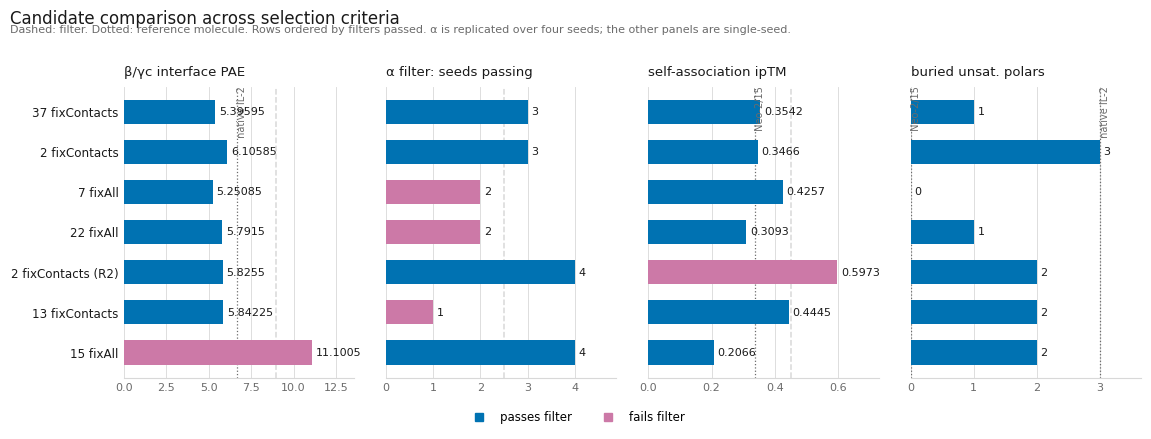

In [ ]:
# One panel per criterion, rows ordered by filters passed. Dashed lines
# are filters, dotted lines are reference molecules. The buried-polar
# panel has no filter and shows both references, since it describes
# feasibility rather than selection
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

FIG = f"{PROJ}/figures"; os.makedirs(FIG, exist_ok=True)
INK, MUTED, RULE = "#1a1a1a", "#6b6b6b", "#d8d8d8"
PASS, FAIL = "#0072B2", "#CC79A7"

def shortn(d):
    p = d.split("_")
    return f"{p[2]} {p[3]}" + (" (R2)" if p[2] == "2" and p[4] == "0" else "")

ordc = C.sort_values(["gates_passed","bgc"], ascending=[False,True]).index.tolist()
y = np.arange(len(ordc))[::-1]

PANELS = [
    ("bgc",           "β/γc interface PAE",      G_BGC,  "lower",
     {"native IL-2": M.loc["ctrl_IL2",["pae_beta","pae_gc"]].mean()}),
    ("seeds_passing", "α filter: seeds passing",   2.5,    "higher", {}),
    ("self_iptm",     "self-association ipTM",   G_SELF, "lower",
     {"Neo-2/15": M.loc["ctrl_Neo","self_iptm"]}),
    ("buns",          "buried unsat. polars",    None,   "lower",
     {"native IL-2": M.loc["ctrl_IL2","buns"], "Neo-2/15": M.loc["ctrl_Neo","buns"]}),
]

fig, axes = plt.subplots(1, 4, figsize=(11.6, 3.9), sharey=True)
for ax, (col, title, gate, better, refs) in zip(axes, PANELS):
    v = C.loc[ordc, col].values
    ok = (v < gate) if (gate and better == "lower") else \
         (v >= gate) if gate else np.ones(len(v), bool)
    cols_ = [PASS if o else FAIL for o in ok]
    ax.barh(y, v, height=0.6, color=cols_, zorder=3)
    for yi, vv in zip(y, v):
        ax.text(vv + 0.02*max(v), yi, f"{vv:g}", va="center", ha="left",
                fontsize=8, color=INK, zorder=4)
    if gate:
        ax.axvline(gate, color=RULE, lw=1.1, ls="--", zorder=2)
    for lbl, rv in refs.items():
        ax.axvline(rv, color=MUTED, lw=0.9, ls=":", zorder=2)
        ax.text(rv, len(ordc)-0.35, f" {lbl}", fontsize=7, color=MUTED,
                rotation=90, va="top", ha="left")
    ax.set_title(title, fontsize=9.5, color=INK, loc="left", pad=8)
    ax.set_xlim(0, max(v)*1.22)
    ax.xaxis.grid(True, color=RULE, lw=0.6, zorder=0); ax.set_axisbelow(True)
    for s in ("top","right","left"): ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(RULE)
    ax.tick_params(colors=MUTED, length=0, labelsize=8)

axes[0].set_yticks(y)
axes[0].set_yticklabels([shortn(d) for d in ordc], fontsize=8.6, color=INK)
axes[0].tick_params(axis="y", length=0)

fig.legend(handles=[
    Line2D([0],[0], marker="s", ls="none", color=PASS, label="passes filter"),
    Line2D([0],[0], marker="s", ls="none", color=FAIL, label="fails filter")],
    frameon=False, fontsize=8.5, loc="lower center", ncol=2,
    bbox_to_anchor=(0.5, -0.07))

fig.suptitle("Candidate comparison across selection criteria",
             fontsize=12, color=INK, x=0.012, ha="left", y=1.02)
fig.text(0.012, 0.96,
         "Dashed: filter. Dotted: reference molecule. Rows ordered by filters passed. "
         "α is replicated over four seeds; the other panels are single-seed.",
         fontsize=8, color=MUTED, ha="left")

fig.tight_layout()
for ext in ("png","pdf"):
    fig.savefig(f"{FIG}/candidate_comparison.{ext}", dpi=300, bbox_inches="tight")
print("wrote", f"{FIG}/candidate_comparison.png")
plt.show()

#### Results
Ten molecules, 24 columns. Three structural metrics from ESMFold, four receptor-engagement metrics, seven α counter-screen columns, including the replicated ones, two self-association columns, and six feasibility columns.

1. The missing cells are informative and are left visible. The three controls have no ESMFold metrics, because controls were never passed through Stage 4: they entered at
Stage 5. More consequentially, the scrambled control is absent from the feasibility scan and the self-association screen entirely. Those two screens therefore have no negative control at all, which is why neither contributes a gate anchored on one.

2. Filters result
| design | β/γc PAE | filter | seeds passing | filter | self-ipTM | filter | passed |
|---|---|---|---|---|---|---|---|
| 37_fixContacts_2 | 5.40 | ✓ | 3 | ✓ | 0.354 | ✓ | 3 |
| 2_fixContacts_3 | 6.11 | ✓ | 3 | ✓ | 0.347 | ✓ | 3 |
| 7_fixAll_3 | 5.25 | ✓ | 2 | ✗ | 0.426 | ✓ | 2 |
| 22_fixAll_0 | 5.79 | ✓ | 2 | ✗ | 0.309 | ✓ | 2 |
| 2_fixContacts_0 (R2) | 5.83 | ✓ | 4 | ✓ | 0.597 | ✗ | 2 |
| 13_fixContacts_3 | 5.84 | ✓ | 1 | ✗ | 0.444 | ✓ | 2 |
| 15_fixAll_4 | 11.10 | ✗ | 4 | ✓ | 0.207 | ✓ | 2 |


Two designs pass all three gates, not one. `37_fixContacts_2` and `2_fixContacts_3` tie at 3 of 3. No single candidate is defensible on this evidence, which is consistent with every earlier stage: the ranking changed at each of five evaluation layers, and the two that survive here were not the top two at any of them.

3. Every design clears the target-binding filter except one. `15_fixAll_4` at interface PAE 11.10 is worse than the scrambled control's 8.97: the only design in the project that fails a threshold set by a sequence which cannot fold. It passes the other two filters, including all four α seeds, which illustrates why the filters are reported separately rather than summed into a score: a molecule can look selective by failing to engage anything.

4. The Round 2 candidate fails on self-association, and plausibly because of the substitution that fixed its packing. `2_fixContacts_0` differs from `2_fixContacts_3` at
one position — tyrosine for arginine at 22. That change removed two buried unsatisfied polar atoms and improved seed stability. It also raised self-ipTM from 0.347 to 0.597, the highest of any design. The master table shows a mechanism for that. Removing an arginine moved net charge at pH 7 from -6.9 to -1.1, and pI from 5.03 to 6.09. A near-neutral protein at physiological pH loses the electrostatic self-repulsion that keeps it monomeric, which is the standard explanation for aggregation near the isoelectric point. The substitution traded a core
packing defect for a colloidal stability one. This is n = 1 and the two effects were not separately tested, but it is the kind of cross-metric link the joined table exists to make visible, and previous notebooks could not have shown it alone.

5. Unfiltered feasibility

| design | BUNS | free Cys | pI | charge pH 7 | instability |
|---|---|---|---|---|---|
| 37_fixContacts_2 | 1 | 0 | 4.70 | -11.0 | 36.1 |
| 7_fixAll_3 | 0 | 1 | 9.10 | +2.6 | 40.0 |
| 2_fixContacts_0 | 2 | 0 | 6.09 | -1.1 | 48.3 |
| 13_fixContacts_3 | 2 | 0 | 4.48 | -13.0 | 51.2 |
| 22_fixAll_0 | 1 | 1 | 4.92 | -7.4 | 60.7 |
| 2_fixContacts_3 | 3 | 0 | 5.03 | -6.9 | 61.2 |
| 15_fixAll_4 | 2 | 1 | 5.27 | -4.0 | 65.8 |
| native IL-2 | 3 | 3 | 6.70 | -0.4 | 51.2 |
| Neo-2/15 | 0 | 0 | 4.95 | -5.8 | 65.1 |


`37_fixContacts_2` is the strongest of the two gate-passers on every fesibility column: 1 buried unsatisfied polar against 3, the lowest instability index in the panel at 36.1, which is better than both references, no free cysteine, and a net charge of -11 well away from its pI. `2_fixContacts_3` has three buried unsatisfied polars, the most of any design and equal to native IL-2.

`pad2_len100_7_fixAll_3` is an outlier worth noting: the only basic design (pI 9.10, charge +2.6), zero buried unsatisfied polars, and the best target engagement in the panel. It fails only the α gate, at 2 of 4 seeds.

Neither reference is clean. Native IL-2 carries three free cysteines and three buried unsatisfied polars; Neo-2/15's instability index of 65.1 is the second-worst in the table.
Feasibility metrics do not separate molecules that work from molecules that do not work.

#### Conclusions
1. Two candidates pass all three filters, no single winner. `37_fixContacts_2` and `2_fixContacts_3` tie at 3 of 3. This is the correct outcome to report rather than a tie broken by preference, and it is consistent with the ranking having changed at every previous layer.

2. On the ungated feasibility columns, `37_fixContacts_2` is clearly the stronger of the two: one buried unsatisfied polar against three, the lowest instability index in the panel including both references, and a net charge far from its pI. That is the basis on which it is treated as the lead candidate, and it is a weaker basis than a filter, because no
control-anchored threshold exists for any fesibility metric.

3. Filters must be reported separately, not summed: `15_fixAll_4` passes two of three, including all four α-replication seeds, while failing target engagement against a scrambled sequence. A molecule that engages nothing looks selective. A composite score would have
ranked it mid-panel.

4. Master table revealed a trade-off neither source notebook could show: The Round 2 substitution that removed a packing defect also moved net charge from -6.9 to -1.1 and raised self-association from 0.347 to 0.597, which is the highest of any design. Fixing one liability created another, and the link is visible only with the liability scan and the self-association screen in the same row.

5. One gate is post-hoc and is declared as such. The self-association threshold was set after seeing the data, because that screen's positive control, monomeric native IL-2 at
0.869, is a false positive. Neo-2/15 anchors it instead. This is the only threshold in the project not derived from a control, and it is the one most open to challenge.

6. Feasibility does not discriminate. Native IL-2 has 3 free cysteines and 3 buried unsatisfied polars. Neo-2/15 has an instability index worse than 5 of 7 designs. Both molecules work. These metrics describe manufacturability, not function, and are carried for that purpose only.

7. The α counter-screen asks a question that is ill-posed for de novo molecules: Native IL-2's two receptor surfaces share zero residues. Every de novo molecule in the panel shares
35-58% of them, including Neo-2/15 at 54.3%, which is experimentally selective. Since the measure cannot separate Neo-2/15 from a shuffled sequence at 58.3%, it cannot rank designs, and since α and the target receptors compete for the same surface,selectivity here is an affinity competition rather than the presence or absence of a binding site.



#### What is not in the master table and why

The master table is assembled from the metrics that survived evaluation. Roughly a third of the candidate metrics did not and they left no columns behind.

Each was discarded because of a control, not because it gave an inconvenient answer about a design. The right-hand column points to the notebook where each was tested and rejected.

| metric | intended purpose | why discarded | found in |
|---|---|---|---|
| ipTM contrast (pre-registered primary) | selectivity | scored a shuffled sequence as more selective (0.164) than Neo-2/15 (0.130) | complex prediction |
| interface PAE contrast | selectivity, replacement for the above | could not separate Neo-2/15 (7.66) from shuffled (7.57) | complex prediction |
| global ipTM | complex confidence | shuffled sequence 0.870 against native IL-2 0.908 | complex prediction<br> orthogonal cross-check |
| actifptm | interface-focused confidence | 0.981 / 0.980 / 0.980 for a natural cytokine, a clinical-stage design and an untested design | orthogonal cross-check |
| pDockQ | interface quality | less variation between molecules than between the predictor's own five networks | orthogonal cross-check |
| ipSAE | interface confidence | as above | orthogonal cross-check |
| β·γc pairwise ipTM | receptor-pair confidence | 0.860 ± 0.005 across three unrelated ligands — blind to what is bound to it | orthogonal cross-check |
| ProteinMPNN score | predicting foldability | within-arm correlation with pLDDT of -0.17 and -0.02; quartile χ² test null | structure prediction |
| ESM-2 pseudo-log-likelihood | sequence quality | placed Neo-2/15 and native IL-2 at or below a composition-matched shuffled floor | structure prediction |
| α steric clearance at 3.5 Å (pre-registered) | α exclusion | rejected the native IL-2/IL-2Rα crystal structure as clashing | backbone generation |
| single-seed α confidence | α discrimination | interface area ranges 769-1202 Å² between seeds and the contacting residues overlap by only 42% | replication and counter-screens |
| epitope overlap | α discrimination | could not separate Neo-2/15 (54.3%) from shuffled (58.3%) | replication and counter-screens |

Note 1: One retained metric is reported with a failed control rather than discarded. The self-association screen scores monomeric native IL-2 as the strongest self-associator in the panel: ctrl_IL2, self_iptm = 0.869, visible in the table above. It is kept with
Neo-2/15 as its anchor instead, and the threshold derived that way is the only post-hoc one
in the project. See refinement notebook.

Note 2: Two filters were uninformative rather than wrong, and are reported as null results. The motif-geometry gate in the second step passed all 152 backbones at a quarter of its threshold. The whole-chain and motif agreement gates in ESMFold validation step removed only three designs between them beyond what the confidence filter had already removed, so a three-filter funnel was in practice one filter.

Note 3: Two columns are retained specifically as evidence of a failure.alpha_iptm_s0 is kept beside alpha_iptm_mean and seeds_passing, so the single-seed value and the four-seed replicated value can be compared directly. They frequently disagree, which is the point.

Note 4: The filters below are therefore triage over a reduced set of metrics, not a verdict. The three findings that matter most — that the α counter-screen measures competition for a shared
surface, that the α interface is not placed consistently between runs, and
that confidence metrics systematically favour idealised geometry over evolved geometry. They are not expressible as any threshold, and none of them appears in this table.

Note 5: No folded negative control: the target-engagement gate is anchored on a non-folding shuffle, so it establishes a proteinness floor rather than a binding floor.

Note 6: One pre-registered gate was run and is not represented in this table. The signalling-geometry gate (γc Cα RMSD < 2.0 Å after superposition on IL-2Rβ, relative to the predicted native complex) was specified before Stage 5 and executed in the additional-metrics notebook:

| molecule | γc orientation RMSD | clears 2.0 Å |
|---|---|---|
| Neo-2/15 | 1.50 | yes |
| 2_fixContacts_0 (R2) | 1.09 | yes |
| 2_fixContacts_3 | 1.48 | yes |
| 22_fixAll_0 | 1.49 | yes |
| 37_fixContacts_2 | 2.07 | no |
| 7_fixAll_3 | 2.10 | no |
| 15_fixAll_4 | 2.31 | no |
| 13_fixContacts_3 | 3.14 | no |

The lead candidate fails it, but the co-leader passes. It is excluded from the gate count for one reason: it is a single-seed measurement on a ternary panel that was never replicated, whereas the α panel was replicated four times and showed ipTM swings up to 0.26 and PAE swings up to 5.9 near the decision threshold. A 0.07 Å margin on an unreplicated geometric comparison between two predicted complexes is not a verdict, and the same quantity measured with AlphaFold2 inverts the ordering (cross-check notebook).

It is nonetheless the only pre-registered criterion in the project that separates the two gate-passing candidates, and it separates them against the lead. The accurate statement of the outcome is therefore: two candidates pass all three control-anchored filters; 37_fixContacts_2 is preferred on ungated feasibility columns; and a pre-registered geometric criterion, at one seed and under one of two predictors, prefers 2_fixContacts_3. Replicating the ternary panel across seeds is the first thing that would resolve this and is the top item of outstanding work.